In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 17.2 — Frobenius algebras: native spiders versus the group example (17.38)

**Source.** SMSA 7.8, 2026-11-05 (local `smsa.pdf`, SHA-256 `6922b174…813b8fe`). References are section and equation numbers of that version.

**Translation conventions.** `f >> g` is SMSA's $g\circ f$ (first $f$, then $g$); `f @ g` is $f\otimes g$ with the left factor on the left. Native DisCoPy drawings read **top to bottom**, SMSA reads bottom to top; left-to-right order is unchanged. Only built-in DisCoPy 1.2.2 objects and methods are used: no custom functions, classes or rewrite rules. Checks print the computed and expected values with a comparison result and continue when a comparison is `False`.

Definition 17.2.8 allows a general Frobenius algebra. The source example is translated first with typed boxes and the actual coefficients of (17.38). The later native `frobenius.Spider` example adds **specialness and commutativity**. These are additional mathematical assumptions, not simply different drawing styles.

Reading the current source bottom to top, (17.35) splits the right input and multiplies the left pair: `(Id @ Delta) >> (mu @ Id)`. Equation (17.36) splits the left input and multiplies the right pair. The two laws share `mu >> Delta`.

In [1]:
from discopy import frobenius, symmetric, tensor
from discopy.drawing import Equation
import numpy as np

**The source example (17.38).** For $G=\mathbb Z_2=\{e,g\}$ with basis $(\delta_e,\delta_g)$: $\delta_a*\delta_b=\delta_{ab}$, $\;\Delta(\delta_a)=|G|\sum_h \delta_{ah}\otimes\delta_{h^{-1}}$, $\;\varepsilon(\delta_a)=|G|^{-1}\delta_{a,e}$, $\;\eta=\delta_e$. These are ordinary typed boxes in the `symmetric` module with the arrays written out (input axes first). Nothing about spiders is assumed: as free diagrams the two sides of (17.35) stay different, and only the evaluated arrays can agree. A deliberately wrong counit value shows that the counit check is not automatic.

In [2]:
B = symmetric.Ty('B')
mu_G = symmetric.Box('mu_G', B @ B, B)
Delta_G = symmetric.Box('Delta_G', B, B @ B)
eta_G = symmetric.Box('eta_G', symmetric.Ty(), B)
eps_G = symmetric.Box('eps_G', B, symmetric.Ty())
mu_arr = np.zeros((2, 2, 2))      # mu_arr[a, b, c] = 1 if c = a*b  (indices 0=e, 1=g, product = addition mod 2)
Delta_arr = np.zeros((2, 2, 2))   # Delta_arr[a, b, c] = |G| if b*c = a, i.e. b = a h, c = h^{-1}
for a in range(2):
    for b in range(2):
        mu_arr[a, b, (a + b) % 2] = 1
        Delta_arr[a, b, (a - b) % 2] = 2
eta_arr = np.array([1.0, 0.0])
eps_arr = np.array([0.5, 0.0])
H = tensor.Functor({B: 2}, {mu_G: mu_arr, Delta_G: Delta_arr, eta_G: eta_arr, eps_G: eps_arr}, dom=symmetric.Category(), dtype=float)
left_G = (symmetric.Id(B) @ Delta_G) >> (mu_G @ symmetric.Id(B))
middle_G = mu_G >> Delta_G
right_G = (Delta_G @ symmetric.Id(B)) >> (symmetric.Id(B) @ mu_G)
print('(17.35) as free box diagrams, lhs == rhs:', left_G == middle_G, '   (boxes carry no relations)')
print('counit axiom (eps x id) o Delta = id:', np.array_equal(H(Delta_G >> (eps_G @ symmetric.Id(B))).array, np.eye(2)))
H_wrong = tensor.Functor({B: 2}, {Delta_G: Delta_arr, eps_G: np.array([1.0, 0.0])}, dom=symmetric.Category(), dtype=float)
print('control, counit axiom with eps(delta_e) = 1 instead of 1/2:', np.array_equal(H_wrong(Delta_G >> (eps_G @ symmetric.Id(B))).array, np.eye(2)))
print('(17.35) in F(Z2):', H(left_G) == H(middle_G), '   (17.36) in F(Z2):', H(right_G) == H(middle_G))
print('mu o Delta in F(Z2):')
print(H(Delta_G >> mu_G).array)
print('eps o eta in F(Z2):', H(eta_G >> eps_G).array)
print('special in the sense of (17.42)?', np.array_equal(H(Delta_G >> mu_G).array, np.eye(2)) and float(H(eta_G >> eps_G).array) == 2)
for label, diagram in [('17.35', left_G), ('17.36', right_G)]:
    print(label, 'actual entries:', H(diagram).array.reshape(4,4))
    print('Expected common entries:', H(middle_G).array.reshape(4,4))
actual_counit = H(Delta_G >> (eps_G @ symmetric.Id(B))).array
wrong_counit = H_wrong(Delta_G >> (eps_G @ symmetric.Id(B))).array
print('Source counit actual:', actual_counit, '; expected:', np.eye(2))
print('Wrong counit actual:', wrong_counit, '; expected:', np.eye(2))


(17.35) as free box diagrams, lhs == rhs: False    (boxes carry no relations)
counit axiom (eps x id) o Delta = id: True
control, counit axiom with eps(delta_e) = 1 instead of 1/2: False
(17.35) in F(Z2): True    (17.36) in F(Z2): True
mu o Delta in F(Z2):
[[4. 0.]
 [0. 4.]]
eps o eta in F(Z2): 0.5
special in the sense of (17.42)? False
17.35 actual entries: [[2. 0. 0. 2.]
 [0. 2. 2. 0.]
 [0. 2. 2. 0.]
 [2. 0. 0. 2.]]
Expected common entries: [[2. 0. 0. 2.]
 [0. 2. 2. 0.]
 [0. 2. 2. 0.]
 [2. 0. 0. 2.]]
17.36 actual entries: [[2. 0. 0. 2.]
 [0. 2. 2. 0.]
 [0. 2. 2. 0.]
 [2. 0. 0. 2.]]
Expected common entries: [[2. 0. 0. 2.]
 [0. 2. 2. 0.]
 [0. 2. 2. 0.]
 [2. 0. 0. 2.]]
Source counit actual: [[1. 0.]
 [0. 1.]] ; expected: [[1. 0.]
 [0. 1.]]
Wrong counit actual: [[2. 0.]
 [0. 2.]] ; expected: [[1. 0.]
 [0. 1.]]


**A concrete inverse from (17.41).** Take two distinctly typed copies $A_G,B$ of the source-normalized $\mathbb Z_2$ algebra above. Choose $f(\delta_e)=\delta_e$, $f(\delta_g)=-\delta_g$, so its matrix in these bases is $F=\operatorname{diag}(1,-1)$. The four comparisons below check that this particular $f$ preserves multiplication, unit, comultiplication and counit, as required by (17.39)–(17.40).

SMSA 7.8, Lemma 17.2.15, p. 377 supplies the candidate inverse
\[
h=((\varepsilon_B\circ\mu_B)\otimes\mathrm{id}_{A_G})\circ
(\mathrm{id}_B\otimes f\otimes\mathrm{id}_{A_G})\circ
(\mathrm{id}_B\otimes(\Delta_{A_G}\circ\eta_{A_G})).
\]
Read its native diagram top to bottom: create the pair in $A_G\otimes A_G$, apply $f$ to the left member, and contract the two $B$ wires with $\varepsilon_B\circ\mu_B$. Here $\Delta\eta=2(\delta_e\otimes\delta_e+\delta_g\otimes\delta_g)$ and the pairing has matrix $\frac12 I_2$, so their factors cancel. We evaluate the supplied formula for this finite example, with both composites printed. This does not perform the general graphical proof requested in Task 17.2.16.

multiplication (17.39) actual: [[[ 1.  0.]
  [ 0. -1.]]

 [[ 0. -1.]
  [ 1.  0.]]] ; expected: [[[ 1.  0.]
  [ 0. -1.]]

 [[ 0. -1.]
  [ 1.  0.]]] ; exact match: True
unit (17.39) actual: [1. 0.] ; expected: [1. 0.] ; exact match: True
comultiplication (17.40) actual: [[[ 2.  0.]
  [ 0.  2.]]

 [[ 0. -2.]
  [-2.  0.]]] ; expected: [[[ 2.  0.]
  [ 0.  2.]]

 [[ 0. -2.]
  [-2.  0.]]] ; exact match: True
counit (17.40) actual: [0.5 0. ] ; expected: [0.5 0. ] ; exact match: True
(17.41) actual boundary: B -> A_G ; expected: B -> A_G ; match: True
candidate inverse actual: [[ 1.  0.]
 [ 0. -1.]] ; expected: [[ 1.  0.]
 [ 0. -1.]] ; exact match: True
h o f on A_G actual: [[1. 0.]
 [0. 1.]] ; expected: [[1. 0.]
 [0. 1.]] ; exact match: True
f o h on B actual: [[1. 0.]
 [0. 1.]] ; expected: [[1. 0.]
 [0. 1.]] ; exact match: True


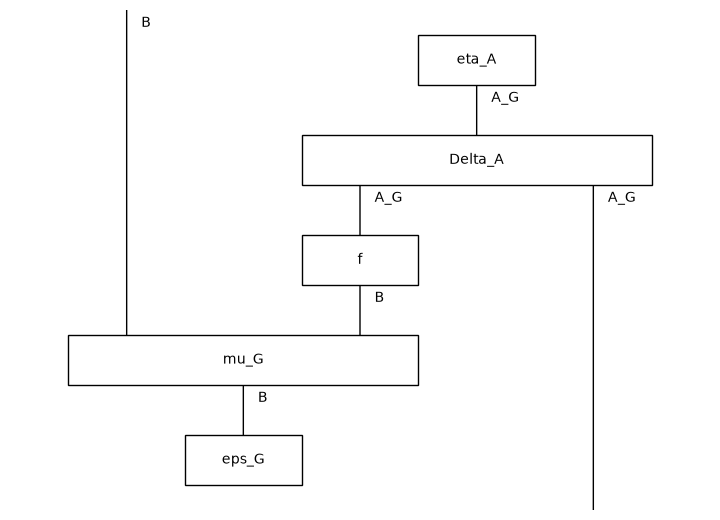

In [3]:
# SMSA 7.8, pp. 377-378, (17.39)-(17.41): one source-normalized Z2 instance.
A_G = symmetric.Ty('A_G')
mu_A = symmetric.Box('mu_A', A_G @ A_G, A_G)
Delta_A = symmetric.Box('Delta_A', A_G, A_G @ A_G)
eta_A = symmetric.Box('eta_A', symmetric.Ty(), A_G)
eps_A = symmetric.Box('eps_A', A_G, symmetric.Ty())
f_AB = symmetric.Box('f', A_G, B)
F_arr = np.diag([1., -1.])
L = tensor.Functor({A_G: 2, B: 2},
    {mu_A: mu_arr, Delta_A: Delta_arr, eta_A: eta_arr, eps_A: eps_arr,
     mu_G: mu_arr, Delta_G: Delta_arr, eta_G: eta_arr, eps_G: eps_arr,
     f_AB: F_arr}, dom=symmetric.Category(), dtype=float)
for name, actual, expected in [
    ('multiplication (17.39)', mu_A >> f_AB, (f_AB @ f_AB) >> mu_G),
    ('unit (17.39)', eta_A >> f_AB, eta_G),
    ('comultiplication (17.40)', f_AB >> Delta_G, Delta_A >> (f_AB @ f_AB)),
    ('counit (17.40)', f_AB >> eps_G, eps_A)]:
    print(name, 'actual:', L(actual).array, '; expected:', L(expected).array,
          '; exact match:', np.array_equal(L(actual).array, L(expected).array))
h_BA = ((symmetric.Id(B) @ (eta_A >> Delta_A))
        >> (symmetric.Id(B) @ f_AB @ symmetric.Id(A_G))
        >> ((mu_G >> eps_G) @ symmetric.Id(A_G)))
print('(17.41) actual boundary:', h_BA.dom, '->', h_BA.cod,
      '; expected:', B, '->', A_G, '; match:', h_BA.dom == B and h_BA.cod == A_G)
print('candidate inverse actual:', L(h_BA).array,
      '; expected:', F_arr, '; exact match:', np.array_equal(L(h_BA).array, F_arr))
for name, composite in [('h o f on A_G', f_AB >> h_BA), ('f o h on B', h_BA >> f_AB)]:
    print(name, 'actual:', L(composite).array, '; expected:', np.eye(2),
          '; exact match:', np.array_equal(L(composite).array, np.eye(2)))
h_BA.draw(figsize=(7, 5))


In [4]:
# Deliberately double only the B counit used in the contraction.
L_wrong = tensor.Functor({A_G: 2, B: 2},
    {eta_A: eta_arr, Delta_A: Delta_arr, f_AB: F_arr,
     mu_G: mu_arr, eps_G: 2 * eps_arr}, dom=symmetric.Category(), dtype=float)
print('wrong-counit inverse actual:', L_wrong(h_BA).array, '; expected inverse:', F_arr,
      '; exact match:', np.array_equal(L_wrong(h_BA).array, F_arr))
print('wrong-counit h o f actual:', L_wrong(f_AB >> h_BA).array,
      '; expected:', np.eye(2),
      '; exact match:', np.array_equal(L_wrong(f_AB >> h_BA).array, np.eye(2)))


wrong-counit inverse actual: [[ 2.  0.]
 [ 0. -2.]] ; expected inverse: [[ 1.  0.]
 [ 0. -1.]] ; exact match: False
wrong-counit h o f actual: [[2. 0.]
 [0. 2.]] ; expected: [[1. 0.]
 [0. 1.]] ; exact match: False


**Restricted native spider model.** Now impose specialness and commutativity and use the native structural generators.

(17.35) lhs : A @ Spider(1, 2, A) >> Spider(2, 1, A) @ A    boundary A @ A -> A @ A
rhs : Spider(2, 1, A) >> Spider(1, 2, A)    boundary A @ A -> A @ A
(17.36) lhs : Spider(1, 2, A) @ A >> A @ Spider(2, 1, A)    boundary A @ A -> A @ A


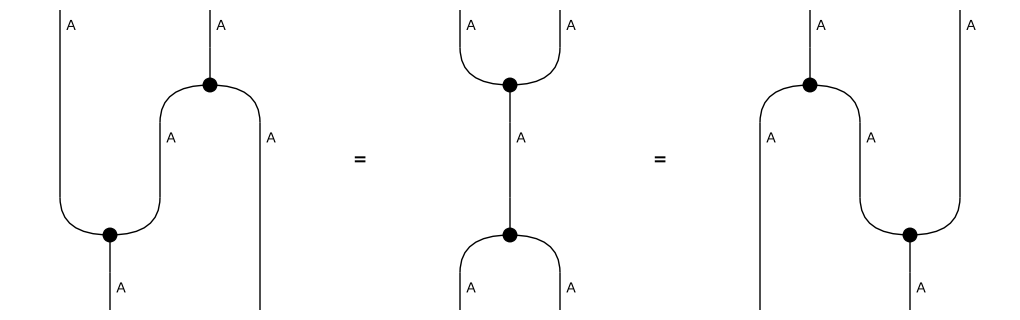

In [5]:
A = frobenius.Ty('A')
mu, Delta = frobenius.Spider(2, 1, A), frobenius.Spider(1, 2, A)
eta, eps = frobenius.Spider(0, 1, A), frobenius.Spider(1, 0, A)
left = (frobenius.Id(A) @ Delta) >> (mu @ frobenius.Id(A))     # (17.35)
middle = mu >> Delta                                           # common right side
right = (Delta @ frobenius.Id(A)) >> (frobenius.Id(A) @ mu)    # (17.36)
for name, d in [('(17.35) lhs', left), ('rhs', middle), ('(17.36) lhs', right)]:
    print(name, ':', d, '   boundary', d.dom, '->', d.cod)
Equation(left, middle, right).draw(figsize=(10, 3))

**Which built-in operation decides equality?** In this release `normal_form()` only performs the rigid (snake) normalisation, so it leaves the three diagrams distinct. The spider-fusion rules live in `to_hypergraph()`: two spider diagrams are equal as hypergraphs exactly when they have the same connectivity. Converting back with `to_diagram()` shows the fused spider, the case $p=q=2$, $\xi=1$ of Lemma 17.2.20, (17.46). Two controls show that the test can fail: the identity and the swap on two wires are not that spider.

In [6]:
print('equal as free diagrams:', left == middle == right)
print('normal_form() identifies them:', left.normal_form() == middle.normal_form() == right.normal_form())
print('to_hypergraph() identifies them:', left.to_hypergraph() == middle.to_hypergraph() == right.to_hypergraph())
print('fused form of each side:', left.to_hypergraph().to_diagram(), '|', middle.to_hypergraph().to_diagram(), '|', right.to_hypergraph().to_diagram())
print('Lemma 17.2.20, (17.46) with p = q = 2: equal to the single spider:', middle.to_hypergraph() == frobenius.Spider(2, 2, A).to_hypergraph())
print('control, identity on two wires == spider:', frobenius.Id(A @ A).to_hypergraph() == frobenius.Spider(2, 2, A).to_hypergraph())
print('control, swap of two wires == spider:   ', frobenius.Swap(A, A).to_hypergraph() == frobenius.Spider(2, 2, A).to_hypergraph())
print('specialness (17.42), mu o Delta = id as hypergraphs:', (Delta >> mu).to_hypergraph() == frobenius.Id(A).to_hypergraph())

equal as free diagrams: False
normal_form() identifies them: False
to_hypergraph() identifies them: True
fused form of each side: Spider(2, 2, A) | Spider(2, 2, A) | Spider(2, 2, A)
Lemma 17.2.20, (17.46) with p = q = 2: equal to the single spider: True
control, identity on two wires == spider: False
control, swap of two wires == spider:    False
specialness (17.42), mu o Delta = id as hypergraphs: True


**Evaluating spiders.** A tensor functor needs only the dimension of `A`; the spider arrays are built in (Kronecker deltas in the chosen basis). This is the algebra of *pointwise* multiplication of coordinate vectors. The second part of (17.42) evaluates to $\dim A$.

In [7]:
G = tensor.Functor({A: 2}, {}, dom=frobenius.Category(), dtype=int)
print('spider mu as a 4 x 2 array (input pair, output):')
print(G(mu).array.reshape(4, 2))
print('mu o Delta:')
print(G(Delta >> mu).array)
print('eps o eta =', G(eta >> eps).array, '  dim A = 2  match:', int(G(eta >> eps).array) == 2)
print('Frobenius law in the spider model:', G(left) == G(middle) == G(right))

spider mu as a 4 x 2 array (input pair, output):
[[1 0]
 [0 0]
 [0 0]
 [0 1]]
mu o Delta:
[[1 0]
 [0 1]]
eps o eta = 2   dim A = 2  match: True
Frobenius law in the spider model: True


**Optional normalization change.** Equation (17.38) with the printed factors $|G|$ and $|G|^{-1}$ is a Frobenius algebra, but **not** special: $\mu\circ\Delta=|G|^2\,\mathrm{id}$ and $\varepsilon\circ\eta=|G|^{-1}$. Rescaling $\Delta\mapsto\lambda\Delta$, $\varepsilon\mapsto\lambda^{-1}\varepsilon$ keeps every axiom; the choice $\lambda=|G|^{-2}$ (that is, $|G|^{-1}$ in $\Delta$ and $|G|$ in $\varepsilon$) makes it special. The rescaled structure below is a comparison model, not a correction to SMSA. Its displayed dyadic entries are exactly represented in binary floating point here.

**Change of basis as a diagram.** Let $e_0=(\delta_e+\delta_g)/2$ and $e_1=(\delta_e-\delta_g)/2$, the characters of $\mathbb Z_2$ divided by $|G|$. The matrix $P$ with these columns is a box $B\to B$; conjugating each structure map by $P$ expresses it in the new basis. The result is compared with the native spider arrays.

special version: mu o Delta =
[[1. 0.]
 [0. 1.]]   eps o eta = 2.0
mu actual: [[[1. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 1.]]] expected spider: [[[1 0]
  [0 0]]

 [[0 0]
  [0 1]]] exact match: True
Delta actual: [[[1. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 1.]]] expected spider: [[[1 0]
  [0 0]]

 [[0 0]
  [0 1]]] exact match: True
eta actual: [1. 1.] expected spider: [1 1] exact match: True
eps actual: [1. 1.] expected spider: [1 1] exact match: True
mu in the character basis, as a 4 x 2 array:
[[1. 0.]
 [0. 0.]
 [0. 0.]
 [0. 1.]]


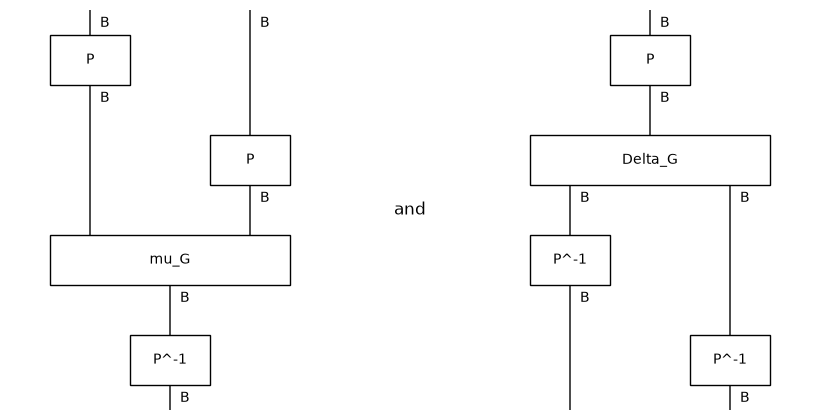

In [8]:
P = symmetric.Box('P', B, B)
Pinv = symmetric.Box('P^-1', B, B)
P_mat = np.array([[0.5, 0.5],
                  [0.5, -0.5]])            # columns: e_0, e_1 in delta coordinates
K = tensor.Functor({B: 2}, {mu_G: mu_arr, Delta_G: Delta_arr / 4, eta_G: eta_arr, eps_G: 4 * eps_arr,
                            P: P_mat.T, Pinv: np.linalg.inv(P_mat).T}, dom=symmetric.Category(), dtype=float)
mu_new = (P @ P) >> mu_G >> Pinv
Delta_new = P >> Delta_G >> (Pinv @ Pinv)
eta_new = eta_G >> Pinv
eps_new = P >> eps_G
Equation(mu_new, Delta_new, symbol="and").draw(figsize=(8, 4))
print('special version: mu o Delta =')
print(K(Delta_G >> mu_G).array, '  eps o eta =', K(eta_G >> eps_G).array)
for name, d, s in [('mu', mu_new, mu), ('Delta', Delta_new, Delta), ('eta', eta_new, eta), ('eps', eps_new, eps)]:
    print(name, 'actual:', K(d).array, 'expected spider:', G(s).array, 'exact match:', np.array_equal(K(d).array, G(s).array))
print('mu in the character basis, as a 4 x 2 array:')
print(np.round(K(mu_new).array.reshape(4, 2), 6))

**Scope.** Hypergraph equality establishes the shown identities for native special commutative spiders. The source-normalized Z2 example checks the two Frobenius composites, a counit law, and its specialness scalars; this cell sequence is not an exhaustive test of all algebra/coalgebra axioms. The optional rescaling and basis change are verified for Z2. Formula (17.41) is translated and both inverse composites are checked for the displayed nontrivial map between two copies of the source-normalized Z2 algebra. The general graphical proof of Lemma 17.2.15 remains outside this finite-model check.